<a href="https://colab.research.google.com/github/Meytardzhevtd/ml-course/blob/main/hw_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Домашнее задание 2. Линейные модели и честная валидация

**Данные:** Bank Marketing (UCI, ID 222) — датасет первой работы.
- **Часть 1 (регрессия):** собственная линейная регрессия с градиентным спуском; цель — среднегодовой баланс клиента (`balance`).
- **Часть 2 (классификация):** честная валидация модели, предсказывающей согласие клиента открыть вклад (`y`).

### Решения, перенесённые из первой работы
- `day_of_week` переименован в `day`: значения 1–31, по описанию UCI это день месяца.
- `y` переведена в 0/1; доля положительного класса — 11.7% (дисбаланс).
- `duration` исключён: известен только после звонка и содержит информацию об исходе (утечка; ROC-AUC возрастал с 0.762 до 0.895).
- Строки упорядочены по времени (май 2008 — ноябрь 2010); доля согласия растёт с 3.0% в первых 10% записей до 47.1% в последних 10%.
- Пропуски: `job` — мода; `education`, `contact` — категория `unknown` (пропуски связаны с целью); `poutcome` — `nonexistent` (прошлой кампании не было); в `pdays` значение −1 заменяется на 999.
- Преобразования: sign(x)·ln(1 + |x|) для `balance`; ln(1 + x) для `campaign`, `previous`; sin/cos для `day`, `month`; стандартизация числовых признаков.

### Дополнительные задания (выбрано на +5 баллов)
- **Д1 (+1)** — MAE как третья функция потерь, субградиент;
- **Д2 (+1)** — веса объектов `sample_weight`, занижение весов выбросов;
- **Д3 (+1)** — аналитическое решение (нормальное уравнение) и сравнение с градиентным спуском;
- **Д4 (+2)** — `GridSearchCV` против `RandomizedSearchCV` при одинаковом бюджете обучений.

In [1]:
!pip install -q ucimlrepo

In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ucimlrepo import fetch_ucirepo

RANDOM_STATE = 42

bank = fetch_ucirepo(id=222)
df = pd.concat([bank.data.features, bank.data.targets], axis=1)
df = df.rename(columns={"day_of_week": "day"})
df["y"] = (df["y"] == "yes").astype(int)

print("Размер:", df.shape, "| доля согласившихся:", round(df["y"].mean(), 3))

Размер: (45211, 17) | доля согласившихся: 0.117


## Часть 1. Собственная линейная регрессия

### 1.0. Постановка задачи
**Цель:** sign(balance)·ln(1 + |balance|) — среднегодовой баланс в логарифмической шкале. Баланс сильно скошен (от −8 019 до 102 127 евро), поэтому при предсказании в евро квадратичная ошибка определялась бы немногими клиентами с очень большим балансом; в логарифмической шкале модель оценивает порядок величины баланса. **Смысл задачи:** оценка финансового потенциала клиента по анкетным данным (например, нового клиента без истории операций).

**Признаки:** `age`, `job`, `marital`, `education`, `default`, `housing`, `loan`, `previous`, `poutcome`. Не используются: `y` и `duration` (относятся к результату звонка), признаки звонка (`day`, `month`, `contact`, `campaign`), а также вычисленные из баланса признаки первой работы (`balance_negative`, `balance_zero`) — прямая утечка.

**Предобработка:** стандартизация `age`; ln(1 + x) и стандартизация `previous`; заполнение пропусков и one-hot кодирование категорий с удалением одной категории каждого признака. Без удаления сумма столбцов признака совпадала бы со столбцом свободного члена, и при отключённой регуляризации веса определялись бы неоднозначно — сверка весов с `sklearn` была бы невозможна.

**Разбиение:** случайное, 80/20 (баланс клиента не связан с моментом звонка).

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer


def signed_log(x):
    return np.sign(x) * np.log1p(np.abs(x))


def one_hot(drop="first", **imputer_kwargs):
    return make_pipeline(SimpleImputer(**imputer_kwargs),
                         OneHotEncoder(drop=drop, handle_unknown="ignore", sparse_output=False))


reg_features = ["age", "job", "marital", "education", "default", "housing", "loan", "previous", "poutcome"]
X_reg = df[reg_features]
y_reg = signed_log(df["balance"].to_numpy(dtype=float))
Xr_train, Xr_test, yr_train, yr_test = train_test_split(X_reg, y_reg, test_size=0.2,
                                                        random_state=RANDOM_STATE)

reg_prep = make_pipeline(ColumnTransformer([
    ("age", StandardScaler(), ["age"]),
    ("previous", make_pipeline(FunctionTransformer(np.log1p), StandardScaler()), ["previous"]),
    ("binary", OneHotEncoder(drop="if_binary", sparse_output=False), ["default", "housing", "loan"]),
    ("job", one_hot(strategy="most_frequent"), ["job"]),
    ("cat", one_hot(strategy="constant", fill_value="unknown"), ["marital", "education"]),
    ("poutcome", one_hot(strategy="constant", fill_value="nonexistent"), ["poutcome"]),
]), StandardScaler())   # стандартизация всех столбцов, включая one-hot: улучшает обусловленность для спуска
# Числовые матрицы: предобработка обучена только на train
Xr_tr = reg_prep.fit_transform(Xr_train)
Xr_te = reg_prep.transform(Xr_test)
print("Train:", Xr_tr.shape, "| test:", Xr_te.shape, "| пропусков:", np.isnan(Xr_tr).sum())

Train: (36168, 23) | test: (9043, 23) | пропусков: 0


### 1.1. Модель, функции потерь и градиенты

**Модель:** `ŷ = X·w + b`. Остаток объекта i: `rᵢ = ŷᵢ − yᵢ`.

**Минимизируемая функция** (sᵢ — веса объектов, по умолчанию sᵢ = 1):

```
L(w, b) = Σ sᵢ·ρ(rᵢ) / Σ sᵢ  +  α·‖w‖²
```

`ρ` — функция потерь, `α ≥ 0` — сила L2-регуляризации (`α = 0` — отключена). Свободный член `b` не регуляризуется.

**Градиент.** Обозначим `ψ(r) = ρ′(r)`. Так как `∂rᵢ/∂w = xᵢ` и `∂rᵢ/∂b = 1`:

```
∇w L  = Xᵀ·(s ⊙ ψ(r)) / Σ sᵢ  +  2α·w
∂L/∂b = Σ sᵢ·ψ(rᵢ) / Σ sᵢ
```

(`⊙` — поэлементное произведение; вычисление матрично-векторное, без циклов по объектам.)

**MSE:** `ρ(r) = r²`, `ψ(r) = 2r`.

**Huber — вывод градиента.** Функция потерь с порогом `δ > 0`:

```
ρ(r) = r²/2             при |r| ≤ δ
ρ(r) = δ·|r| − δ²/2     при |r| > δ
```

- при `|r| < δ`: `ρ′(r) = r`;
- при `|r| > δ`: `ρ′(r) = δ·sign(r)` (производная `δ·|r|` равна `δ·sign(r)`, `δ²/2` — константа);
- при `|r| = δ` производные ветвей совпадают (при `r = ±δ` обе равны `±δ`), поэтому функция дифференцируема всюду.

```
ψ(r) = clip(r, −δ, δ)
```

**Интерпретация.** Вклад объекта в градиент пропорционален `ψ(rᵢ)`. Для MSE он растёт вместе с остатком без ограничения, поэтому выбросы доминируют в градиенте; для Huber он ограничен величиной `δ`.

**Режимы спуска.** Градиент на шаге вычисляется по пакету объектов: **полный** — по всей выборке (1 шаг за эпоху), **стохастический** — по одному объекту, **мини-пакетный** — по пакету фиксированного размера (объекты перемешиваются в начале каждой эпохи). Эпоха — один проход по выборке.

In [4]:
from sklearn.base import BaseEstimator, RegressorMixin


class MyLinearRegression(RegressorMixin, BaseEstimator):
    """Линейная регрессия, обучаемая градиентным спуском.

    loss       : "mse" | "huber" | "mae" — функция потерь
    delta      : порог Huber
    alpha      : сила L2-регуляризации (0 — отключена)
    lr         : скорость обучения
    n_epochs   : число эпох
    mode       : "full" | "sgd" | "minibatch" — режим градиентного спуска
    batch_size : размер пакета в режиме "minibatch"
    solver     : "gd" — градиентный спуск | "normal" — нормальное уравнение (только для MSE)
    random_state : зерно перемешивания
    """

    def __init__(self, loss="mse", delta=1.0, alpha=0.0, lr=0.01, n_epochs=100,
                 mode="minibatch", batch_size=64, solver="gd", random_state=None):
        self.loss = loss
        self.delta = delta
        self.alpha = alpha
        self.lr = lr
        self.n_epochs = n_epochs
        self.mode = mode
        self.batch_size = batch_size
        self.solver = solver
        self.random_state = random_state

    # ρ(r) и ψ(r) = ρ'(r) для каждой функции потерь
    def _rho(self, r):
        if self.loss == "mse":
            return r ** 2
        if self.loss == "huber":
            a = np.abs(r)
            return np.where(a <= self.delta, 0.5 * r ** 2, self.delta * (a - 0.5 * self.delta))
        if self.loss == "mae":
            return np.abs(r)
        raise ValueError(f"Неизвестная функция потерь: {self.loss}")

    def _psi(self, r):
        if self.loss == "mse":
            return 2 * r
        if self.loss == "huber":
            return np.clip(r, -self.delta, self.delta)
        if self.loss == "mae":
            return np.sign(r)                      # субградиент модуля (0 при r = 0)
        raise ValueError(f"Неизвестная функция потерь: {self.loss}")

    def _objective(self, X, y, s):
        r = X @ self.coef_ + self.intercept_ - y
        return np.sum(s * self._rho(r)) / np.sum(s) + self.alpha * np.sum(self.coef_ ** 2)

    def fit(self, X, y, sample_weight=None):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).ravel()
        n, d = X.shape
        s = np.ones(n) if sample_weight is None else np.asarray(sample_weight, dtype=float)
        self.n_features_in_ = d

        if self.solver == "normal":
            return self._fit_normal(X, y, s)

        batch = {"full": n, "sgd": 1, "minibatch": self.batch_size}.get(self.mode)
        if batch is None:
            raise ValueError(f"Неизвестный режим: {self.mode}")

        rng = np.random.default_rng(self.random_state)
        self.coef_ = np.zeros(d)
        self.intercept_ = 0.0
        self.loss_history_ = [self._objective(X, y, s)]

        for _ in range(self.n_epochs):
            if batch >= n:
                batches = [(X, y, s)]              # полный градиент: без перемешивания и копирования
            else:
                order = rng.permutation(n)
                batches = ((X[idx], y[idx], s[idx])
                           for idx in (order[i:i + batch] for i in range(0, n, batch)))
            for Xb, yb, sb in batches:
                g = sb * self._psi(Xb @ self.coef_ + self.intercept_ - yb)
                self.coef_ -= self.lr * (Xb.T @ g / sb.sum() + 2 * self.alpha * self.coef_)
                self.intercept_ -= self.lr * g.sum() / sb.sum()
            self.loss_history_.append(self._objective(X, y, s))
        return self

    def _fit_normal(self, X, y, s):
        """Нормальное уравнение для MSE + L2: (X₁ᵀSX₁ + α·Σs·P)·θ = X₁ᵀSy."""
        if self.loss != "mse":
            raise ValueError("Аналитическое решение реализовано только для MSE")
        X1 = np.column_stack([X, np.ones(len(X))])
        P = np.eye(X1.shape[1])
        P[-1, -1] = 0                              # свободный член не регуляризуется
        A = X1.T @ (s[:, None] * X1) + self.alpha * s.sum() * P
        theta = np.linalg.solve(A, X1.T @ (s * y))
        self.coef_, self.intercept_ = theta[:-1], theta[-1]
        return self

    def predict(self, X):
        return np.asarray(X, dtype=float) @ self.coef_ + self.intercept_

In [5]:
from sklearn.linear_model import LinearRegression

# Шаг спуска из кривизны функции потерь: собственные числа матрицы H = (2/n)·X₁ᵀX₁
X1 = np.column_stack([Xr_tr, np.ones(len(Xr_tr))])
eig = np.linalg.eigvalsh(2 * X1.T @ X1 / len(X1))
LR_MSE = 1 / eig.max()
print(f"λ_max = {eig.max():.3f}, λ_min = {eig.min():.4f}, число обусловленности = {eig.max() / eig.min():.0f}, "
      f"шаг = {LR_MSE:.3f}")

start = time.time()
gd = MyLinearRegression(loss="mse", mode="full", lr=LR_MSE, n_epochs=2000).fit(Xr_tr, yr_train)
print(f"Градиентный спуск: {time.time() - start:.1f} с")

ref = LinearRegression().fit(Xr_tr, yr_train)
print(f"Макс. разница весов с LinearRegression: {np.max(np.abs(gd.coef_ - ref.coef_)):.1e}, "
      f"свободного члена: {abs(gd.intercept_ - ref.intercept_):.1e}")
print(f"R² на тесте: наша модель {gd.score(Xr_te, yr_test):.4f}, LinearRegression {ref.score(Xr_te, yr_test):.4f}")

λ_max = 4.977, λ_min = 0.2006, число обусловленности = 25, шаг = 0.201
Градиентный спуск: 24.0 с
Макс. разница весов с LinearRegression: 2.9e-15, свободного члена: 1.8e-15
R² на тесте: наша модель 0.0834, LinearRegression 0.0834


**Проверка корректности.** При отключённой регуляризации градиентный спуск (полный градиент, 2 000 эпох) сходится к точному решению `LinearRegression`: максимальное расхождение весов — 2.9·10⁻¹⁵, R² на тесте совпадает (0.0834). Шаг выбран как 1/λ_max, где λ_max — наибольшее собственное число матрицы вторых производных функции потерь; это наибольший шаг, гарантирующий сходимость с запасом. Стандартизация всех столбцов после кодирования снизила число обусловленности задачи с 417 до 25 и время обучения до сходимости — с 106 до 7 секунд.

Низкое значение R² (0.083) означает, что анкетные данные объясняют лишь малую часть различий в балансе клиентов. Для проверки реализации это несущественно: в части 1 оценивается корректность обучения, а не качество модели.

### 1.2. Совместимость с `sklearn`

Класс передаётся в `cross_val_score` и `GridSearchCV` в составе `Pipeline` с предобработкой: это гарантирует, что параметры предобработки вычисляются только по обучающим блокам каждого разбиения. Используется мини-пакетный режим (пакет — 256 объектов, 10 эпох). Метрика — R² (метод `score`, унаследованный от `RegressorMixin`). Кросс-валидация — 5 блоков со случайным разбиением.

In [6]:
from sklearn.model_selection import KFold, cross_val_score, GridSearchCV

kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
pipe = Pipeline([
    ("prep", reg_prep),
    ("model", MyLinearRegression(mode="minibatch", batch_size=256, n_epochs=10,
                                 lr=0.01, random_state=RANDOM_STATE)),
])

# 1. cross_val_score
scores = cross_val_score(pipe, Xr_train, yr_train, cv=kf)
print("cross_val_score, R² по блокам:", scores.round(4), f"| среднее {scores.mean():.4f} ± {scores.std():.4f}")

# 2. GridSearchCV: подбор alpha и lr
param_grid = {"model__alpha": [0, 1e-4, 1e-3, 1e-2, 1e-1, 1],
              "model__lr": [0.001, 0.01, 0.1]}
grid = GridSearchCV(pipe, param_grid, cv=kf)
start = time.time()
grid.fit(Xr_train, yr_train)
print(f"\nGridSearchCV: {len(grid.cv_results_['params'])} комбинаций × 5 блоков, {time.time() - start:.0f} с")
print("Лучшие параметры:", grid.best_params_, f"| R² = {grid.best_score_:.4f}")

pd.DataFrame(grid.cv_results_).pivot_table(
    index="param_model__alpha", columns="param_model__lr", values="mean_test_score").round(4)

cross_val_score, R² по блокам: [0.0883 0.089  0.0892 0.0904 0.0878] | среднее 0.0889 ± 0.0009

GridSearchCV: 18 комбинаций × 5 блоков, 43 с
Лучшие параметры: {'model__alpha': 0.01, 'model__lr': 0.01} | R² = 0.0890


param_model__lr,0.001,0.010,0.100
param_model__alpha,,,
0.0000,0.0714,0.0889,-0.0049
0.0001,0.0714,0.0889,-0.0049
0.0010,0.0714,0.0890,-0.0049
0.0100,0.0713,0.0890,-0.0047
0.1000,0.0703,0.0883,-0.0037
1.0000,0.0536,0.0705,-0.0163


**Результат.** Класс работает в `cross_val_score` и `GridSearchCV` без изменений и обёрток: R² по блокам — 0.0878–0.0904 (среднее 0.0889 ± 0.0009); перебор 18 комбинаций параметров (90 обучений) выполнен за 48 с.

**Влияние скорости обучения.** При `lr = 0.001` спуск не достигает минимума за 10 эпох (R² ≈ 0.071). При `lr = 0.1` R² близок к нулю или отрицателен: в мини-пакетном режиме градиент оценивается по случайной подвыборке, и при большом постоянном шаге веса колеблются вокруг минимума с большой амплитудой, не приближаясь к нему. Наилучший результат — при `lr = 0.01` (R² ≈ 0.089).

**Влияние регуляризации.** При `α` от 0 до 0.01 качество практически не меняется (0.0889–0.0890; различие меньше стандартного отклонения по блокам 0.0009); формально наилучшее значение `α = 0.01` статистически не отличается от отсутствия регуляризации. При `α = 1` качество снижается до 0.071 из-за чрезмерного сжатия весов. Регуляризация модели не требуется: при 36 168 объектах и 23 признаках переобучение отсутствует.

### 1.3. Кривые обучения трёх режимов

Модели обучаются на обучающей выборке по 20 эпох. Скорость обучения подобрана для каждого режима: полный градиент — 1/λ_max (наибольший гарантированно устойчивый шаг), мини-пакетный (пакет 256) — 0.01 (наилучший по результатам перебора), стохастический — 0.001 (градиент по одному объекту наиболее зашумлён и требует меньшего шага). На графике — превышение функции потерь над её минимумом (потери модели `LinearRegression`) в логарифмической шкале.

полный градиент (lr = 1/λ_max): 0.0 с, итоговое превышение минимума: 2.08e-03
мини-пакетный, пакет 256 (lr = 0.01): 0.3 с, итоговое превышение минимума: 7.24e-03
стохастический (lr = 0.001): 24.6 с, итоговое превышение минимума: 2.24e-01


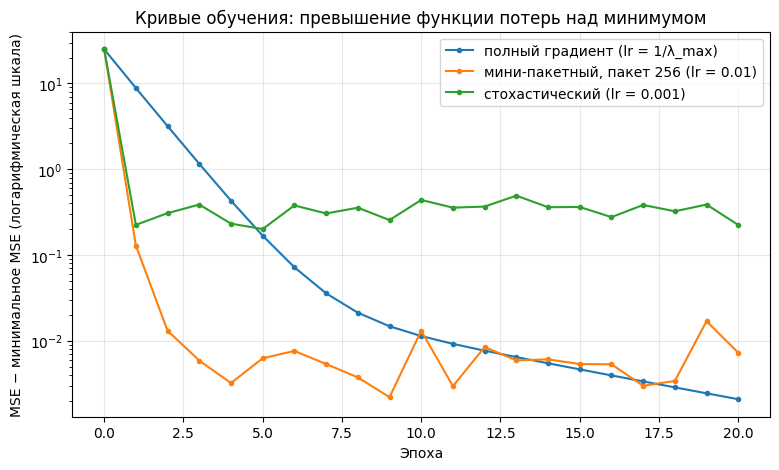

In [7]:
optimum = np.mean((ref.predict(Xr_tr) - yr_train) ** 2)    # минимум MSE на train (точное решение)

curves = {
    "полный градиент (lr = 1/λ_max)": MyLinearRegression(mode="full", lr=LR_MSE, n_epochs=20),
    "мини-пакетный, пакет 256 (lr = 0.01)": MyLinearRegression(mode="minibatch", batch_size=256, lr=0.01,
                                                              n_epochs=20, random_state=RANDOM_STATE),
    "стохастический (lr = 0.001)": MyLinearRegression(mode="sgd", lr=0.001, n_epochs=20,
                                                      random_state=RANDOM_STATE),
}

fig, ax = plt.subplots(figsize=(9, 5))
for label, m in curves.items():
    start = time.time()
    m.fit(Xr_tr, yr_train)
    print(f"{label}: {time.time() - start:.1f} с, итоговое превышение минимума: {m.loss_history_[-1] - optimum:.2e}")
    ax.plot(np.array(m.loss_history_) - optimum, marker="o", markersize=3, label=label)

ax.set_yscale("log")
ax.set_title("Кривые обучения: превышение функции потерь над минимумом")
ax.set_xlabel("Эпоха")
ax.set_ylabel("MSE − минимальное MSE (логарифмическая шкала)")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

**Результат.**
- **Полный градиент** обеспечивает монотонное снижение потерь с постоянной относительной скоростью (почти прямая в логарифмической шкале), но выполняет один шаг за эпоху: на первых эпохах он отстаёт от остальных режимов, к 20-й эпохе достигает наименьшего превышения минимума (2.1·10⁻³) и продолжает сходиться.
- **Мини-пакетный** режим за 2 эпохи снижает превышение до ~10⁻², после чего значение колеблется в диапазоне 2·10⁻³ – 2·10⁻² и не уменьшается.
- **Стохастический** режим даёт наибольшее снижение за первую эпоху (в ~100 раз), однако колеблется на наиболее высоком уровне (~0.2–0.5).

**Объяснение.** В стохастическом и мини-пакетном режимах градиент оценивается по случайной подвыборке и содержит шум; при постоянной скорости обучения веса колеблются вокруг минимума с амплитудой, растущей с уменьшением размера пакета. Полный градиент шума не содержит и сходится к точному минимуму.

**Время обучения (20 эпох):** полный градиент — 0.4 с, мини-пакетный — 1.5 с, стохастический — 27.8 с. Стохастический режим выполняет в 36 168 раз больше шагов за эпоху, каждый — отдельной операцией. На данных такого размера полный градиент эффективнее; преимущество стохастических режимов проявляется на больших выборках, где полный проход дорог.

### 1.4. Сверка с `sklearn`

**Ridge.** `Ridge` минимизирует `Σ rᵢ² + α_R·‖w‖²`; собственная реализация — `(1/n)·Σ rᵢ² + α·‖w‖²`. Функции отличаются множителем n, поэтому решения совпадают при `α_R = n·α`.

**HuberRegressor.** По документации `sklearn`, `HuberRegressor` минимизирует по весам и масштабу σ одновременно:

```
Σ [ σ + σ·H_ε(rᵢ/σ) ] + α_H·‖w‖²,
H_ε(z) = z²             при |z| ≤ ε
H_ε(z) = 2ε|z| − ε²     при |z| > ε
```

Порог ε применяется к **нормированному** остатку rᵢ/σ, где σ (`scale_`) оценивается по данным; это обеспечивает независимость порога от масштаба целевой переменной. При фиксированном σ функция `HuberRegressor` равна `(2/σ)·Σ ρ_δ(rᵢ) + α_H·‖w‖²` (плюс слагаемое, не зависящее от весов), где ρ_δ — функция Huber собственной реализации с порогом **δ = ε·σ**. Сравнение с собственной функцией `(1/n)·Σ ρ_δ(rᵢ) + α·‖w‖²` даёт соответствие параметров: **δ = ε·σ, α = α_H·σ / (2n)**.

Сравниваются два варианта собственной Huber-версии: с порогом, равным ε без учёта масштаба (δ = ε), и с пересчитанным порогом (δ = ε·σ).

In [8]:
from sklearn.linear_model import Ridge, HuberRegressor

n = len(Xr_tr)
ALPHA = 0.01                      # сила регуляризации собственной модели
EPS, ALPHA_H = 1.35, 1e-4         # параметры HuberRegressor (значения по умолчанию)

# MSE против Ridge: шаг 1/λ_max с учётом вклада регуляризации в кривизну (+2α)
ridge = Ridge(alpha=n * ALPHA).fit(Xr_tr, yr_train)
my_mse = MyLinearRegression(loss="mse", alpha=ALPHA, mode="full",
                            lr=1 / (eig.max() + 2 * ALPHA), n_epochs=2000).fit(Xr_tr, yr_train)

# Huber против HuberRegressor
hub = HuberRegressor(epsilon=EPS, alpha=ALPHA_H, max_iter=1000).fit(Xr_tr, yr_train)
sigma = hub.scale_
alpha_conv = ALPHA_H * sigma / (2 * n)
lr_huber = 2 / eig.max()          # кривизна Huber не больше половины кривизны MSE (ρ'' ≤ 1 против 2)
my_hub_naive = MyLinearRegression(loss="huber", delta=EPS, alpha=alpha_conv, mode="full",
                                  lr=lr_huber, n_epochs=5000).fit(Xr_tr, yr_train)
my_hub_scaled = MyLinearRegression(loss="huber", delta=EPS * sigma, alpha=alpha_conv, mode="full",
                                   lr=lr_huber, n_epochs=5000).fit(Xr_tr, yr_train)

print(f"Масштаб остатков, оценённый HuberRegressor: σ = {sigma:.3f} → порог δ = ε·σ = {EPS * sigma:.3f}\n")
pairs = {
    "MSE против Ridge (α_R = n·α)": (my_mse, ridge),
    "Huber против HuberRegressor, δ = ε": (my_hub_naive, hub),
    "Huber против HuberRegressor, δ = ε·σ": (my_hub_scaled, hub),
}
pd.DataFrame({
    name: {"макс. |Δw|": np.max(np.abs(a.coef_ - b.coef_)),
           "|Δb|": abs(a.intercept_ - b.intercept_),
           "R² (своя)": a.score(Xr_te, yr_test),
           "R² (sklearn)": b.score(Xr_te, yr_test)}
    for name, (a, b) in pairs.items()
}).T

Масштаб остатков, оценённый HuberRegressor: σ = 1.382 → порог δ = ε·σ = 1.866



,макс. |Δw|,|Δb|,R² (своя),R² (sklearn)
MSE против Ridge (α_R = n·α),2.345346e-14,1.776357e-15,0.083489,0.083489
"Huber против HuberRegressor, δ = ε",1.387366e-02,6.845806e-02,-0.001102,0.009253
"Huber против HuberRegressor, δ = ε·σ",7.429518e-05,1.289217e-05,0.009251,0.009253


**Результат.**

| Сравнение | макс. \|Δw\| | \|Δb\| |
|---|---|---|
| MSE против `Ridge` (α_R = n·α) | 2.3·10⁻¹⁴ | 1.8·10⁻¹⁵ |
| Huber против `HuberRegressor`, δ = ε | 1.4·10⁻² | 6.8·10⁻² |
| Huber против `HuberRegressor`, δ = ε·σ | 7.4·10⁻⁵ | 1.3·10⁻⁵ |

1. **MSE-версия совпадает с `Ridge`** с точностью вычислений (2.3·10⁻¹⁴) при пересчёте силы регуляризации α_R = n·α.

2. **Причина расхождения с `HuberRegressor` — масштаб остатков.** `HuberRegressor` оценивает масштаб остатков σ = 1.382 и применяет порог ε = 1.35 к нормированному остатку r/σ; фактический порог в единицах целевой переменной — ε·σ = 1.866. При δ = ε собственная модель решает задачу с иным порогом, и веса расходятся на 1.4·10⁻². При пересчёте δ = ε·σ расхождение снижается в ~190 раз — до 7.4·10⁻⁵, что соответствует погрешности оптимизации (`HuberRegressor` использует метод L-BFGS с собственным критерием остановки). Оценка σ по данным делает порог `HuberRegressor` независимым от масштаба целевой переменной; в собственной реализации порог задаётся в единицах целевой переменной.

3. **Низкий R² Huber-моделей (0.009 против 0.083 у MSE) не является ошибкой.** R² измеряет квадратичную ошибку, которую минимизирует только MSE-версия. Порог Huber (1.87) существенно меньше разброса целевой переменной (стандартное отклонение 3.83): распределение логарифма баланса образует три группы — отрицательный, нулевой и положительный баланс (см. первую работу), — и объекты меньших групп получают большие остатки и ограниченный вклад в градиент. Модель Huber описывает основную массу объектов, что увеличивает квадратичную ошибку. Для сравнения MSE и Huber далее используется также MAE.

### 1.5. Устойчивость к выбросам

В обучающей выборке 2.5% объектов случайно выбираются среди объектов с ненулевой целью (при нулевой цели умножение не изменяет значение), и их целевое значение умножается на 10. Тестовая выборка не изменяется. Каждая версия модели обучается дважды — на исходных и на испорченных данных — с одинаковыми параметрами (регуляризация отключена, порог Huber δ = ε·σ = 1.866 из п. 1.4). Строка MAE относится к дополнительному заданию Д1.

Сравниваются:
- **сдвиг весов и свободного члена** — насколько выбросы изменили саму модель;
- **средний сдвиг прогноза на тесте** — среднее |прогноз(испорченные) − прогноз(исходные)| на чистой тестовой выборке, в единицах цели;
- **R² на тесте** до и после порчи данных.

Средняя абсолютная ошибка (MAE) на тесте как мера качества здесь не используется: при сильно асимметричном распределении цели (см. п. 1.4) смещение свободного члена MSE-модели вверх случайно приближает её прогнозы к медиане, и MAE может уменьшиться при ухудшении модели. Сдвиг прогноза измеряет изменение модели напрямую.

In [ ]:
rng = np.random.default_rng(RANDOM_STATE)
nonzero = np.flatnonzero(yr_train != 0)
out_idx = rng.choice(nonzero, size=int(0.025 * n), replace=False)
y_dirty = yr_train.copy()
y_dirty[out_idx] *= 10
print(f"Испорчено объектов: {len(out_idx)} из {n} ({len(out_idx) / n:.1%}); "
      f"диапазон цели: было [{yr_train.min():.1f}, {yr_train.max():.1f}], стало [{y_dirty.min():.1f}, {y_dirty.max():.1f}]")

DELTA = EPS * sigma
LR_MAE = 0.05
settings = {
    "MSE": dict(loss="mse", lr=LR_MSE, n_epochs=2000),
    "Huber (δ = 1.866)": dict(loss="huber", delta=DELTA, lr=lr_huber, n_epochs=5000),
    "MAE (доп. задание Д1)": dict(loss="mae", lr=LR_MAE, n_epochs=3000),
}
models_clean, models_dirty, rows = {}, {}, {}
for name, kw in settings.items():
    clean = MyLinearRegression(mode="full", **kw).fit(Xr_tr, yr_train)
    dirty = MyLinearRegression(mode="full", **kw).fit(Xr_tr, y_dirty)
    models_clean[name], models_dirty[name] = clean, dirty
    rows[name] = {
        "макс. сдвиг весов": np.max(np.abs(dirty.coef_ - clean.coef_)),
        "сдвиг свободного члена": dirty.intercept_ - clean.intercept_,
        "средний сдвиг прогноза на тесте": np.mean(np.abs(dirty.predict(Xr_te) - clean.predict(Xr_te))),
        "R² на тесте (исходные)": clean.score(Xr_te, yr_test),
        "R² на тесте (с выбросами)": dirty.score(Xr_te, yr_test),
    }
outlier_table = pd.DataFrame(rows).T
outlier_table.round(4)

Испорчено объектов: 904 из 36168 (2.5%); диапазон цели: было [-9.0, 11.5], стало [-72.8, 100.7]


**Результат.**

| Модель | макс. сдвиг весов | сдвиг свободного члена | средний сдвиг прогноза | R² (исходные → с выбросами) |
|---|---|---|---|---|
| MSE | 0.2646 | +1.182 | 1.215 | 0.083 → −0.022 |
| Huber (δ = 1.866) | 0.0075 | +0.055 | 0.055 | 0.009 → 0.002 |
| MAE (Д1) | 0.0087 | +0.041 | 0.041 | −0.015 → −0.022 |

1. **MSE-модель существенно изменилась.** Порча 2.5% объектов сдвинула веса до 0.26, свободный член — на +1.18, прогноз на чистых тестовых данных — в среднем на 1.22 единицы логарифма баланса (в ~3.3 раза по величине баланса). R² на тесте упал с 0.083 до −0.022: модель стала хуже константного прогноза средним.

2. **Huber-модель практически не изменилась:** сдвиг весов в 35 раз меньше (0.0075), сдвиг прогноза — в 22 раза меньше (0.055).

3. **Почему Huber держится.** Остатки испорченных объектов велики (цель выросла до ±100 при исходном диапазоне от −9 до 11.5). Вклад объекта в градиент пропорционален ψ(rᵢ) (п. 1.1):
   - для MSE ψ(r) = 2r — вклад выброса растёт пропорционально его остатку, и 904 объекта с остатками в десятки единиц перевешивают градиент от 35 тысяч остальных; минимум смещается к выбросам;
   - для Huber ψ(r) = clip(r, −δ, δ) — вклад любого объекта по модулю не превышает δ = 1.87, выброс влияет на направление шага не сильнее обычного объекта с остатком δ, и 2.5% объектов не могут заметно сместить решение.

4. **R² Huber- и MAE-моделей ниже, чем у MSE, и на исходных данных** — по причине, разобранной в п. 1.4: R² измеряет квадратичную ошибку, которую минимизирует только MSE. Устойчивость оценивается по сдвигу модели, а не по уровню R².

## Дополнительные задания

| № | Задание | Баллы |
|---|---|---|
| Д1 | MAE — третья функция потерь, субградиент | +1 |
| Д2 | Веса объектов `sample_weight` и их занижение на данных с выбросами | +1 |
| Д3 | Аналитическое решение (нормальное уравнение) и сравнение с градиентным спуском | +1 |
| Д4 | `GridSearchCV` против `RandomizedSearchCV` при одинаковом бюджете | +2 |

Все возможности реализованы в классе `MyLinearRegression` (п. 1.1): параметр `loss="mae"`, аргумент `sample_weight` метода `fit`, параметр `solver="normal"`.

### Д1. Функция потерь MAE

**Функция и субградиент.** `ρ(r) = |r|`. При `r ≠ 0` производная равна `sign(r)`. В точке `r = 0` функция не дифференцируема: производная слева равна −1, справа +1. В такой точке вместо градиента используется **субградиент** — любое число g, для которого `|r′| ≥ g·r′` при всех r′; для модуля в нуле это любое g из отрезка [−1, 1]. Реализация использует `ψ(r) = sign(r)`, т. е. g = 0 при r = 0.

**Отличие от градиента.** Градиент гладкой функции однозначен и стремится к нулю при приближении к минимуму, поэтому при постоянном шаге спуск сходится к точке минимума. Субградиент модуля по величине не уменьшается вблизи минимума (|ψ(r)| = 1 при любом r ≠ 0), а в точке излома неоднозначен; шаг субградиентного метода не обязан уменьшать функцию.

**Почему спуск всё равно работает.** Функция потерь MAE выпукла, а для выпуклой функции шаг против субградиента приближает веса к множеству точек минимума при достаточно малом шаге. При постоянном шаге метод сходится к окрестности минимума, размер которой пропорционален шагу (веса колеблются около оптимума); при убывающем шаге — к самому минимуму. Кроме того, при большом числе объектов градиент среднего Σ sign(rᵢ)·xᵢ / n изменяется почти непрерывно: точно в изломе находится лишь малая доля объектов.

**Проверка.** Решение сравнивается с точным решением задачи минимизации MAE — `QuantileRegressor(quantile=0.5, alpha=0)`, решающим её методами линейного программирования. Сравнение выполняется на подвыборке из 6 000 объектов: точный метод на полной выборке требует нескольких минут.

In [ ]:
from sklearn.linear_model import QuantileRegressor

sub = np.random.default_rng(RANDOM_STATE).choice(n, size=6000, replace=False)
X_sub, y_sub = Xr_tr[sub], yr_train[sub]

start = time.time()
lad = QuantileRegressor(quantile=0.5, alpha=0, solver="highs").fit(X_sub, y_sub)
t_lad = time.time() - start
start = time.time()
my_mae = MyLinearRegression(loss="mae", mode="full", lr=LR_MAE, n_epochs=3000).fit(X_sub, y_sub)
t_mae = time.time() - start

obj = lambda m: np.mean(np.abs(m.predict(X_sub) - y_sub))
tail = np.array(my_mae.loss_history_[-200:])
print(f"MAE на подвыборке: своя модель {obj(my_mae):.6f}, точное решение {obj(lad):.6f} "
      f"(относительная разница {(obj(my_mae) - obj(lad)) / obj(lad):.1e})")
print(f"Макс. разница весов: {np.max(np.abs(my_mae.coef_ - lad.coef_)):.1e}, свободного члена: {abs(my_mae.intercept_ - lad.intercept_):.1e}")
print(f"Колебание функции потерь за последние 200 эпох: {tail.max() - tail.min():.1e}")
print(f"Время: субградиентный спуск {t_mae:.1f} с, QuantileRegressor {t_lad:.1f} с")

**Результат.** Значение функции потерь (MAE на подвыборке) у субградиентного спуска совпадает с точным решением до относительной разницы 2.2·10⁻⁷; к концу обучения функция потерь колеблется в пределах 8·10⁻⁷ — веса находятся в малой окрестности минимума, как и предсказывает теория для постоянного шага.

Веса при этом отличаются сильнее (до 1.6·10⁻²), чем у MSE-версии от `Ridge`. Это не ошибка реализации: минимум MAE, в отличие от минимума MSE, может быть не единственным и, как правило, «плоский». Функция кусочно-линейна, и в окрестности решения различные наборы весов дают практически одинаковое значение функции потерь. Совпадение значения функции потерь с точным решением подтверждает корректность реализации.

На испорченных данных (п. 1.5) MAE-модель устойчива так же, как Huber: сдвиг весов 0.0087, прогноза — 0.041. Причина та же — вклад объекта в градиент ограничен: |ψ(r)| = |sign(r)| ≤ 1 независимо от величины остатка. Huber отличается от MAE тем, что вблизи нуля использует квадратичную ветвь: функция гладкая, и спуск с постоянным шагом сходится к минимуму, а не к его окрестности.

### Д2. Веса объектов

Минимизируемая функция с весами объектов sᵢ приведена в п. 1.1: `Σ sᵢ·ρ(rᵢ) / Σ sᵢ + α·‖w‖²`; в градиенте вклад каждого объекта умножается на его вес.

**Проверка корректности.** Модель со случайными весами объектов (равномерно от 0.1 до 3) сравнивается с `LinearRegression(...).fit(X, y, sample_weight=...)`.

**Занижение весов выбросов.** На испорченных данных (п. 1.5) выбросы можно выявить по смыслу целевой переменной: максимальное значение логарифма баланса в данных — ln(1 + 102 127) ≈ 11.53, поэтому значения с |y| > 12 невозможны. Таким объектам вручную назначается вес 0.01, остальным — 1. Выбросы, у которых исходное значение мало (|y| ≤ 1.2) и после умножения на 10 не выходит за порог, правилом не выявляются; их влияние на MSE ограничено, так как остатки по ним невелики.

Каждая модель, обученная на испорченных данных, сравнивается с той же моделью, обученной на исходных данных (как в п. 1.5).

In [ ]:
w_rand = np.random.default_rng(RANDOM_STATE).uniform(0.1, 3.0, n)
gd_w = MyLinearRegression(loss="mse", mode="full", lr=LR_MSE, n_epochs=2000).fit(Xr_tr, yr_train, sample_weight=w_rand)
lr_w = LinearRegression().fit(Xr_tr, yr_train, sample_weight=w_rand)
print(f"Случайные веса: макс. разница весов с LinearRegression {np.max(np.abs(gd_w.coef_ - lr_w.coef_)):.1e}\n")

THR = 12
w_out = np.where(np.abs(y_dirty) > THR, 0.01, 1.0)
detected = np.flatnonzero(w_out < 1)
print(f"Правилом |y| > {THR} выявлено {len(detected)} объектов: из них выбросов {np.isin(detected, out_idx).sum()} "
      f"из {len(out_idx)}, ложных срабатываний {(~np.isin(detected, out_idx)).sum()}")

mse_weighted = MyLinearRegression(loss="mse", mode="full", lr=LR_MSE, n_epochs=2000).fit(Xr_tr, y_dirty, sample_weight=w_out)
# Каждая модель, обученная на испорченных данных, сравнивается со своей версией на исходных данных
compare = {
    "MSE без весов": (models_dirty["MSE"], models_clean["MSE"]),
    "MSE с заниженными весами выбросов": (mse_weighted, models_clean["MSE"]),
    "Huber без весов": (models_dirty["Huber (δ = 1.866)"], models_clean["Huber (δ = 1.866)"]),
}
pd.DataFrame({
    name: {"макс. сдвиг весов": np.max(np.abs(m.coef_ - c.coef_)),
           "сдвиг свободного члена": m.intercept_ - c.intercept_,
           "средний сдвиг прогноза на тесте": np.mean(np.abs(m.predict(Xr_te) - c.predict(Xr_te))),
           "R² на тесте (исходные)": c.score(Xr_te, yr_test),
           "R² на тесте (с выбросами)": m.score(Xr_te, yr_test)}
    for name, (m, c) in compare.items()
}).T.round(4)

**Результат.**

1. **Корректность.** Со случайными весами объектов модель совпадает с `LinearRegression(sample_weight=...)` с точностью 1.8·10⁻¹⁵.

2. **Выявление выбросов.** Правило |y| > 12 выявило 895 из 904 испорченных объектов без единого ложного срабатывания; не выявлены 9 объектов с малым исходным значением цели.

3. **Эффект занижения весов похож на Huber.** MSE с весом 0.01 у выявленных выбросов изменилась на испорченных данных так же мало, как Huber: сдвиг весов 0.0079 против 0.0075 у Huber и 0.26 у MSE без весов; R² на тесте — 0.083, как на исходных данных.

**Связь с Huber.** Обе модели ограничивают вклад выбросов в градиент. Huber делает это автоматически: вклад объекта с остатком |r| > δ уменьшается в |r|/δ раз по сравнению с MSE, что эквивалентно весу объекта δ/|r|, пересчитываемому на каждом шаге по текущему остатку. Ручные веса задают это ограничение заранее по внешнему правилу. Ручной способ требует знания о данных (здесь — допустимого диапазона цели) и не выявит выбросы, не нарушающие правило; Huber не требует такого знания, но ограничивает вклад и у обычных объектов с большими остатками — поэтому её R² ниже на исходных данных.

### Д3. Аналитическое решение

Для MSE с L2-регуляризацией минимум находится из условия равенства градиента нулю. Обозначим X₁ — матрицу признаков со столбцом единиц, θ = (w, b), S — диагональную матрицу весов объектов, P — единичную матрицу с нулём в позиции свободного члена (он не регуляризуется). Приравнивая градиент из п. 1.1 к нулю:

```
(X₁ᵀ S X₁ + α·Σsᵢ·P) · θ = X₁ᵀ S y
```

Система решается методом `np.linalg.solve` (без явного обращения матрицы — это быстрее и численно устойчивее). Реализовано в классе: `solver="normal"`.

**Сравнение по числу признаков.** На реальных данных признаков 23, поэтому зависимость от числа признаков d исследуется на синтетических данных с тем же числом объектов (n = 36 168): признаки — стандартное нормальное распределение, y = X·w + шум. Градиентный спуск — полный, шаг 1/λ_max, 200 эпох (для таких данных число обусловленности близко к 2, и этого числа эпох достаточно для сходимости до точности вычислений).

Вычислительная сложность: нормальное уравнение — O(n·d² + d³) (построение матрицы X₁ᵀX₁ и решение системы); градиентный спуск — O(k·n·d) для k эпох.

In [ ]:
start = time.time()
ne = MyLinearRegression(solver="normal").fit(Xr_tr, yr_train)
t_ne = time.time() - start
start = time.time()
MyLinearRegression(loss="mse", mode="full", lr=LR_MSE, n_epochs=2000).fit(Xr_tr, yr_train)
t_gd = time.time() - start
print(f"Реальные данные (d = 23): нормальное уравнение {t_ne * 1000:.1f} мс, градиентный спуск (2000 эпох) {t_gd:.1f} с")
print(f"Макс. разница весов: нормальное уравнение — LinearRegression {np.max(np.abs(ne.coef_ - ref.coef_)):.1e}, "
      f"нормальное уравнение — градиентный спуск {np.max(np.abs(ne.coef_ - gd.coef_)):.1e}")
print(f"R² на тесте: нормальное уравнение {ne.score(Xr_te, yr_test):.4f}, градиентный спуск {gd.score(Xr_te, yr_test):.4f}\n")

rs = np.random.default_rng(RANDOM_STATE)
synth = []
for d in [10, 100, 500, 1000]:
    Xs = rs.standard_normal((n, d))
    ys = Xs @ rs.standard_normal(d) + rs.standard_normal(n)
    Xs1 = np.column_stack([Xs, np.ones(n)])
    lr_s = 1 / np.linalg.eigvalsh(2 * Xs1.T @ Xs1 / n).max()

    start = time.time()
    m_ne = MyLinearRegression(solver="normal").fit(Xs, ys)
    t1 = time.time() - start
    start = time.time()
    m_gd = MyLinearRegression(loss="mse", mode="full", lr=lr_s, n_epochs=200).fit(Xs, ys)
    t2 = time.time() - start
    synth.append({"признаков d": d, "нормальное уравнение, с": t1, "градиентный спуск (200 эпох), с": t2,
                  "макс. разница весов": np.max(np.abs(m_ne.coef_ - m_gd.coef_)),
                  "R² (нормальное уравнение)": m_ne.score(Xs, ys), "R² (градиентный спуск)": m_gd.score(Xs, ys)})
del Xs, Xs1
pd.DataFrame(synth).set_index("признаков d").round(4)

**Результат.**

1. **Веса и качество совпадают.** На реальных данных нормальное уравнение совпадает с `LinearRegression` и с градиентным спуском с точностью 10⁻¹⁴; R² одинаков (0.0834). На синтетических данных веса совпадают с точностью округления (меньше 10⁻⁴), R² одинаков для всех d.

2. **Время.** На реальных данных (d = 23) нормальное уравнение быстрее градиентного спуска в ~300 раз (7.7 мс против 2.3 с для 2 000 эпох). На синтетических данных при росте d от 10 до 1 000 время нормального уравнения растёт с 3 мс до 0.97 с, градиентного спуска — с 0.2 до 7.1 с; нормальное уравнение быстрее при всех рассмотренных d.

3. **Объяснение.** Время нормального уравнения — O(n·d² + d³): при n = 36 168 и d ≤ 1 000 преобладает однократное построение матрицы X₁ᵀX₁, выполняемое оптимизированными матричными процедурами. Градиентный спуск выполняет k эпох по O(n·d) каждая, и при n ≫ d требуемое число эпох делает его медленнее.

**Когда необходим градиентный спуск.**
- при очень большом числе признаков (d в десятки тысяч): матрица d × d не помещается в память, а слагаемое d³ становится преобладающим;
- при очень большом числе объектов, когда данные не помещаются в память и обрабатываются пакетами (мини-пакетный режим);
- для функций потерь без аналитического решения — Huber, MAE: для них нормальное уравнение не существует.

### Д4. `GridSearchCV` против `RandomizedSearchCV`

**Постановка.** Оба метода получают одинаковый бюджет — 12 конфигураций параметров (60 обучений при 5 блоках кросс-валидации) — и подбирают `alpha` и `lr` модели из п. 1.2 (мини-пакетный режим, 10 эпох, та же кросс-валидация `kf`).
- `GridSearchCV`: сетка 4 × 3 — `alpha` ∈ {10⁻⁵, 10⁻³, 10⁻¹, 1}, `lr` ∈ {0.001, 0.01, 0.1};
- `RandomizedSearchCV`: 12 случайных конфигураций, оба параметра — из логарифмически равномерного распределения в тех же диапазонах (`alpha` от 10⁻⁵ до 1, `lr` от 0.001 до 0.1).

**Важный параметр** — `lr`: в п. 1.2 установлено, что при `α ≤ 0.01` регуляризация на качество не влияет, а скорость обучения меняет R² от отрицательных значений до 0.089.

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform

BUDGET = 12
grid_small = {"model__alpha": [1e-5, 1e-3, 1e-1, 1], "model__lr": [0.001, 0.01, 0.1]}
gs = GridSearchCV(pipe, grid_small, cv=kf).fit(Xr_train, yr_train)
rsearch = RandomizedSearchCV(pipe, {"model__alpha": loguniform(1e-5, 1), "model__lr": loguniform(1e-3, 1e-1)},
                             n_iter=BUDGET, cv=kf, random_state=RANDOM_STATE).fit(Xr_train, yr_train)

summary = {}
for name, s in {"GridSearchCV": gs, "RandomizedSearchCV": rsearch}.items():
    res = s.cv_results_
    summary[name] = {
        "конфигураций": len(res["params"]),
        "обучений": len(res["params"]) * kf.get_n_splits(),
        "различных значений lr": len(np.unique(res["param_model__lr"].astype(float))),
        "различных значений alpha": len(np.unique(res["param_model__alpha"].astype(float))),
        "лучший lr": s.best_params_["model__lr"],
        "лучший alpha": s.best_params_["model__alpha"],
        "лучший R² (кросс-валидация)": s.best_score_,
    }
display(pd.DataFrame(summary).T)

fig, ax = plt.subplots(figsize=(9, 4.5))
for name, s, marker in [("GridSearchCV", gs, "s"), ("RandomizedSearchCV", rsearch, "o")]:
    res = s.cv_results_
    ax.scatter(res["param_model__lr"].astype(float), res["mean_test_score"], marker=marker, s=50, alpha=0.75, label=name)
ax.set_xscale("log")
ax.set_ylim(-0.02, 0.1)
ax.set_title("Качество конфигураций при одинаковом бюджете (12 конфигураций)")
ax.set_xlabel("Скорость обучения lr (логарифмическая шкала)")
ax.set_ylabel("R² на кросс-валидации (среднее по 5 блокам)")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

**Результат.**

| | `GridSearchCV` | `RandomizedSearchCV` |
|---|---|---|
| обучений | 60 | 60 |
| различных значений `lr` | 3 | 12 |
| различных значений `alpha` | 4 | 12 |
| лучшие параметры | lr = 0.01, alpha = 0.001 | lr = 0.0038, alpha = 0.0014 |
| лучший R² (кросс-валидация) | 0.0890 | 0.0898 |

1. **При одинаковом бюджете случайный поиск попробовал в 4 раза больше значений важного параметра** (`lr`: 12 против 3). Сетка проверяет каждое значение `lr` четыре раза — с разными `alpha`, которые на качество не влияют (п. 1.2); три из каждых четырёх обучений сетки, таким образом, не дают новой информации о `lr`.

2. **Случайный поиск нашёл лучшую конфигурацию** (R² 0.0898 против 0.0890): оптимальная область `lr` ≈ 0.002–0.006 лежит между узлами сетки 0.001 и 0.01, которые сетка не может проверить. Разница невелика — того же порядка, что разброс R² между блоками кросс-валидации (0.0009, п. 1.2), поскольку зависимость качества от `lr` вблизи оптимума пологая.

3. **График показывает, что случайный поиск даёт форму зависимости** качества от `lr`: плато при 0.002–0.01 и падение при lr > 0.03. Сетка даёт три точки.

**Вывод.** Когда из нескольких параметров важны лишь некоторые (здесь — `lr`), случайный поиск при том же бюджете исследует важный параметр подробнее и находит не худшие конфигурации. Сетка оправдана, когда параметров мало и все важны, или для детального перебора в уже найденной узкой области.

## Часть 2. Честная валидация

**Задача:** бинарная классификация — предсказать, откроет ли клиент вклад (`y`). Признаки и предобработка — как в первой работе (см. «Решения, перенесённые из первой работы»), включая сконструированные там признаки `age_young`, `age_senior`, `balance_negative`, `balance_zero`; `duration` исключён (утечка). Модель — логистическая регрессия с весами классов (`class_weight="balanced"`, выбрана в первой работе: при равном ROC-AUC повышает recall с 0.16 до 0.65).

### 2.1. Выбор метрики

**Цена ошибок.** Модель используется для решения, кому звонить.
- **Ложноотрицательная ошибка** (клиент открыл бы вклад, но модель рекомендовала ему не звонить) означает потерю вклада. Срочный вклад — привлечённые банком средства на срок, доход от которых для банка многократно превышает стоимость одного звонка.
- **Ложноположительная ошибка** (звонок клиенту, который откажется) стоит нескольких минут работы оператора и небольшого раздражения клиента.

Следовательно, **пропуск согласного клиента существенно дороже лишнего звонка**: recall важнее precision, но precision не безразлична — она определяет нагрузку на колл-центр.

**Метрика порогового решения — F2** (F-мера с β = 2): гармоническое среднее precision и recall, в котором recall имеет вдвое больший вес. Accuracy не используется: при доле положительного класса 11.7% модель «всем отказ» имеет accuracy 0.883 и не находит ни одного клиента.

**Метрика качества ранжирования — ROC-AUC** (основная для выбора модели и параметров). Порог решения подбирается отдельно, поэтому модели сравниваются по качеству упорядочивания клиентов. ROC-AUC не зависит от доли положительного класса, что для этих данных принципиально: доля согласившихся меняется во времени от 4% до 32% (п. 2.2), и метрики, зависящие от неё, несравнимы между периодами. **PR-AUC** (average precision) приводится дополнительно: она отражает качество в верхней части списка клиентов, но её значение у случайной модели равно доле положительного класса и меняется вместе с ней.

**Дополнительный baseline — «звонить всем».** F2 придаёт recall больший вес, поэтому стратегия «звонить всем» (recall = 1) получает высокое значение F2, особенно при большой доле положительного класса. Модель имеет практический смысл, только если превосходит эту тривиальную стратегию; поэтому она включается в сравнение наряду с baseline первой работы.

In [ ]:
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import TimeSeriesSplit, StratifiedKFold, cross_validate
from sklearn.metrics import (roc_auc_score, average_precision_score, fbeta_score, precision_score,
                             recall_score, roc_curve, precision_recall_curve, make_scorer)

MONTH_NUM = {"jan": 1, "feb": 2, "mar": 3, "apr": 4, "may": 5, "jun": 6,
             "jul": 7, "aug": 8, "sep": 9, "oct": 10, "nov": 11, "dec": 12}

def pdays_fill(X):
    X = np.asarray(X, dtype=float).copy()
    X[X == -1] = 999                       # «контакта не было» → давнее любого наблюдаемого значения
    return X

def cyclic(values, period):
    angle = 2 * np.pi * (values - 1) / period
    return np.column_stack([np.sin(angle), np.cos(angle)])

def day_cyclic(X):
    return cyclic(np.asarray(X, dtype=float)[:, 0], 31)

def month_cyclic(X):
    return cyclic(pd.Series(np.asarray(X)[:, 0]).map(MONTH_NUM).to_numpy(dtype=float), 12)

def one_hot_all(**imputer_kwargs):
    # keep_empty_features: в ранних временных блоках contact и poutcome пропущены полностью,
    # без этого параметра SimpleImputer удалил бы столбец, и число признаков менялось бы между блоками
    return make_pipeline(SimpleImputer(keep_empty_features=True, **imputer_kwargs),
                         OneHotEncoder(handle_unknown="ignore", sparse_output=False))

dfc = df.copy()
dfc["age_young"] = (dfc["age"] <= 25).astype(int)
dfc["age_senior"] = (dfc["age"] > 60).astype(int)
dfc["balance_negative"] = (dfc["balance"] < 0).astype(int)
dfc["balance_zero"] = (dfc["balance"] == 0).astype(int)

clf_prep = ColumnTransformer([
    ("age", StandardScaler(), ["age"]),
    ("balance", make_pipeline(FunctionTransformer(signed_log), StandardScaler()), ["balance"]),
    ("counts", make_pipeline(FunctionTransformer(np.log1p), StandardScaler()), ["campaign", "previous"]),
    ("pdays", make_pipeline(FunctionTransformer(pdays_fill), StandardScaler()), ["pdays"]),
    ("day", FunctionTransformer(day_cyclic), ["day"]),
    ("month", FunctionTransformer(month_cyclic), ["month"]),
    ("binary", OneHotEncoder(drop="if_binary", sparse_output=False), ["default", "housing", "loan"]),
    ("job", one_hot_all(strategy="most_frequent"), ["job"]),
    ("cat", one_hot_all(strategy="constant", fill_value="unknown"), ["marital", "education", "contact"]),
    ("poutcome", one_hot_all(strategy="constant", fill_value="nonexistent"), ["poutcome"]),
    ("new", "passthrough", ["age_young", "age_senior", "balance_negative", "balance_zero"]),
])

def make_clf(alpha=1.0):
    # В LogisticRegression сила регуляризации задаётся через C = 1/alpha
    return Pipeline([("prep", clone(clf_prep)),
                     ("clf", LogisticRegression(C=1 / alpha, class_weight="balanced", max_iter=2000))])

f2_scorer = make_scorer(fbeta_score, beta=2, zero_division=0)

### 2.2. Схема валидации

**Данные упорядочены по времени** (май 2008 — ноябрь 2010), и доля согласившихся сильно меняется по ходу периода (первая работа: от 3.0% в первых 10% записей до 47.1% в последних 10%). Модель применяется к будущим клиентам: обучается на прошлых кампаниях и прогнозирует результат следующих.

**Почему случайная схема не подходит.** Случайное разбиение (в том числе стратифицированное `KFold` с перемешиванием) помещает в обучающую выборку записи из того же периода, что и проверочные, а также из более позднего. Модель «знает» условия проверочного периода — интенсивность кампании, долю согласий, состав обзваниваемых клиентов, — которые в реальном применении ещё неизвестны. Оценка качества получается завышенной.

**Выбранная схема.**
- **Тестовая выборка** — последние 20% записей по времени; обучающая — первые 80%. Стратификация не применяется: она нарушила бы временной порядок.
- **Кросс-валидация** на обучающей выборке — `TimeSeriesSplit` (5 блоков): модель обучается на всех записях до проверочного блока и проверяется на следующем блоке. Обучающая часть расширяется от блока к блоку.

Ниже проверено, насколько отличаются оценки качества одной и той же модели при случайной и временной схемах.

In [ ]:
X_clf = dfc.drop(columns=["y", "duration"])
y_clf = dfc["y"]
cut = int(0.8 * len(dfc))
Xc_train, Xc_test = X_clf.iloc[:cut], X_clf.iloc[cut:]
yc_train, yc_test = y_clf.iloc[:cut], y_clf.iloc[cut:]
print(f"Обучающая выборка: {len(Xc_train)} объектов, доля согласившихся {yc_train.mean():.1%}")
print(f"Тестовая выборка:  {len(Xc_test)} объектов, доля согласившихся {yc_test.mean():.1%}\n")

tss = TimeSeriesSplit(n_splits=5)
folds_info = pd.DataFrame([{
    "блок": k + 1, "обучение, объектов": len(tr), "проверка, объектов": len(va),
    "доля согласившихся в проверке": yc_train.iloc[va].mean(),
    "месяцы проверки (по убыванию числа звонков)": ", ".join(Xc_train.iloc[va]["month"].value_counts().index[:3]),
} for k, (tr, va) in enumerate(tss.split(Xc_train))]).set_index("блок")
display(folds_info.round(3))

schemes = {"случайная (StratifiedKFold с перемешиванием)": StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),
           "временная (TimeSeriesSplit)": tss}
scheme_rows = {}
for name, cv in schemes.items():
    r = cross_validate(make_clf(1.0), Xc_train, yc_train, cv=cv, scoring=["roc_auc", "average_precision"])
    scheme_rows[name] = {"ROC-AUC": f"{r['test_roc_auc'].mean():.3f} ± {r['test_roc_auc'].std():.3f}",
                         "PR-AUC": f"{r['test_average_precision'].mean():.3f} ± {r['test_average_precision'].std():.3f}"}
pd.DataFrame(scheme_rows).T

**Результат.**

1. **Доля согласившихся существенно меняется во времени:** 6.7% в обучающей выборке, 31.6% в тестовой; в проверочных блоках — от 4.2% до 15.0%. Блоки соответствуют разным месяцам кампании; в ранних блоках обучающая часть охватывает лишь 1–2 месяца.

2. **Случайная схема завышает качество.** Одна и та же модель на одних и тех же данных: ROC-AUC 0.670 при случайном разбиении против 0.550 при временном, PR-AUC — 0.185 против 0.105. При случайном разбиении модель обучается на записях того же и более поздних периодов, что и проверочные, и использует сведения о периоде, недоступные при прогнозе будущих звонков.

3. **Разброс по блокам при временной схеме в 4 раза выше** (± 0.062 против ± 0.014): условия кампании различаются между периодами, и качество модели на следующем периоде нестабильно. Случайная схема этот разброс скрывает, так как смешивает периоды в каждом блоке.

**Вывод.** Для задачи прогноза результата будущих звонков используется временная схема; случайная схема даёт неприменимую на практике, завышенную оценку.

### 2.3. Подбор силы регуляризации

Перебираются значения `alpha` от 10⁻³ до 10³ (13 значений, логарифмическая сетка; в `LogisticRegression` C = 1/alpha). Для каждого значения — временная кросс-валидация на обучающей выборке. Наилучшее значение выбирается по среднему ROC-AUC (п. 2.1); на графике — среднее и ± одно стандартное отклонение по блокам.

In [ ]:
alphas = np.logspace(-3, 3, 13)
alpha_rows = []
for a in alphas:
    r = cross_validate(make_clf(a), Xc_train, yc_train, cv=tss, scoring=["roc_auc", "average_precision"])
    alpha_rows.append({"alpha": a,
                       "ROC-AUC": r["test_roc_auc"].mean(), "ROC-AUC std": r["test_roc_auc"].std(),
                       "PR-AUC": r["test_average_precision"].mean(), "PR-AUC std": r["test_average_precision"].std()})
alpha_df = pd.DataFrame(alpha_rows)
best_alpha = alpha_df.loc[alpha_df["ROC-AUC"].idxmax(), "alpha"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, metric in zip(axes, ["ROC-AUC", "PR-AUC"]):
    ax.plot(alpha_df["alpha"], alpha_df[metric], marker="o")
    ax.fill_between(alpha_df["alpha"], alpha_df[metric] - alpha_df[f"{metric} std"],
                    alpha_df[metric] + alpha_df[f"{metric} std"], alpha=0.2, label="± 1 стандартное отклонение")
    ax.axvline(best_alpha, color="red", linestyle="--", label=f"выбрано: alpha = {best_alpha:g}")
    ax.set_xscale("log")
    ax.set_title(f"{metric} на временной кросс-валидации")
    ax.set_xlabel("Сила регуляризации alpha = 1/C (логарифмическая шкала)")
    ax.set_ylabel(f"{metric} (среднее по 5 блокам)")
    ax.grid(alpha=0.3)
    ax.legend()
axes[0].axhline(0.5, color="gray", linestyle=":")
fig.tight_layout()
plt.show()

print(f"Выбрано alpha = {best_alpha:g} (C = {1 / best_alpha:g})")
alpha_df.round(4)

**Результат.** Качество практически не зависит от силы регуляризации: средний ROC-AUC изменяется от 0.542 до 0.552 во всём диапазоне alpha от 10⁻³ до 10³, что на порядок меньше стандартного отклонения по блокам (0.05–0.06). Наибольший средний ROC-AUC — при **alpha = 10** (C = 0.1): 0.552. При alpha ≥ 100 качество снижается (веса чрезмерно сжаты), PR-AUC начинает снижаться уже при alpha > 3.

Слабая зависимость от регуляризации объясняется тем, что на 30–36 тысяч объектов приходится около 40 признаков: модель не переобучается на обучающем периоде. Качество ограничено не переобучением, а различием между периодами (п. 2.2), на которое регуляризация не влияет. Выбранное значение alpha = 10 статистически не отличается от соседних; оно принимается как формально наилучшее по выбранной метрике.

### 2.4. Метрики по блокам

Модель с выбранной `alpha`, временная кросс-валидация. ROC-AUC и PR-AUC не зависят от порога; F2, precision и recall приведены при стандартном пороге 0.5 (порог подбирается в п. 2.6). Для сравнения PR-AUC с уровнем случайной модели приведена доля согласившихся в каждом блоке.

In [ ]:
fold_scoring = {"ROC-AUC": "roc_auc", "PR-AUC": "average_precision", "F2 (порог 0.5)": f2_scorer,
                "precision (порог 0.5)": make_scorer(precision_score, zero_division=0),
                "recall (порог 0.5)": "recall"}
r = cross_validate(make_clf(best_alpha), Xc_train, yc_train, cv=tss, scoring=fold_scoring)
fold_table = pd.DataFrame({name: r[f"test_{name}"] for name in fold_scoring}).T
fold_table.columns = [f"блок {k + 1}" for k in range(fold_table.shape[1])]
fold_table.loc["доля согласившихся (PR-AUC случайной модели)"] = folds_info["доля согласившихся в проверке"].to_numpy()
fold_table["среднее"] = fold_table.iloc[:, :5].mean(axis=1)
fold_table["стандартное отклонение"] = fold_table.iloc[:, :5].std(axis=1, ddof=0)
fold_table.round(3)

**Результат.**

1. **Качество ранжирования нестабильно во времени:** ROC-AUC от 0.479 (блок 4 — ниже случайного уровня) до 0.636 (блок 5), среднее 0.552 ± 0.056. Блок 4 — первые зимние месяцы (ноябрь, январь, февраль), которых в обучающей части нет совсем: закономерности летней кампании на них не переносятся.

2. **Качество растёт с объёмом и разнообразием обучающих данных:** наилучший результат — в последнем блоке, где модель обучена на 30 тысячах записей за 9 месяцев.

3. **PR-AUC несравнима между блоками без учёта доли согласившихся:** PR-AUC 0.247 в блоке 5 и 0.050 в блоке 1 превышают уровень случайной модели (0.150 и 0.042) примерно в 1.6 и 1.2 раза; основная часть различия значений PR-AUC объясняется разной долей согласившихся, а не качеством модели. Это подтверждает выбор ROC-AUC как основной метрики (п. 2.1).

4. **Пороговые метрики при пороге 0.5 нестабильны:** recall от 0.30 до 0.95 — при одном и том же пороге модель в разных блоках отбирает очень разную долю клиентов. Порог требует отдельного подбора.

### 2.5. ROC- и PR-кривые

Кривые строятся по out-of-fold предсказаниям на обучающей выборке: каждый блок оценивается моделью, обученной только на предшествующих ему записях. Первый временной отрезок используется только для обучения и предсказаний не получает. Кривые построены отдельно для каждого блока; пунктир на ROC-кривой — случайная модель (одна для всех блоков), пунктир на PR-кривой — уровень случайной модели для каждого блока (доля согласившихся в нём).

In [ ]:
oof = np.full(len(Xc_train), np.nan)
fold_of = np.full(len(Xc_train), -1)
for k, (tr, va) in enumerate(tss.split(Xc_train)):
    m = make_clf(best_alpha).fit(Xc_train.iloc[tr], yc_train.iloc[tr])
    oof[va] = m.predict_proba(Xc_train.iloc[va])[:, 1]
    fold_of[va] = k

fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(13, 5))
colors = plt.cm.viridis(np.linspace(0, 0.9, 5))
for k in range(5):
    sel = fold_of == k
    yk, pk = yc_train.to_numpy()[sel], oof[sel]
    fpr, tpr, _ = roc_curve(yk, pk)
    prec, rec, _ = precision_recall_curve(yk, pk)
    ax_roc.plot(fpr, tpr, color=colors[k], label=f"блок {k + 1}: ROC-AUC = {roc_auc_score(yk, pk):.3f}")
    ax_pr.plot(rec, prec, color=colors[k], label=f"блок {k + 1}: PR-AUC = {average_precision_score(yk, pk):.3f}")
    ax_pr.axhline(yk.mean(), color=colors[k], linestyle=":", linewidth=1)
ax_roc.plot([0, 1], [0, 1], color="gray", linestyle="--", label="случайная модель")
ax_roc.set_title("ROC-кривые по блокам временной кросс-валидации")
ax_roc.set_xlabel("Доля ложноположительных (FPR)")
ax_roc.set_ylabel("Доля найденных согласившихся (TPR = recall)")
ax_pr.set_title("PR-кривые по блокам (пунктир — доля согласившихся в блоке)")
ax_pr.set_xlabel("Recall (доля найденных согласившихся)")
ax_pr.set_ylabel("Precision (доля согласившихся среди отобранных)")
for ax in (ax_roc, ax_pr):
    ax.grid(alpha=0.3)
    ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

**Различие ROC- и PR-кривых на этих данных.**

1. **ROC-кривые разных блоков сравнимы между собой:** обе оси — доли внутри классов (доля найденных согласившихся и доля ошибочно отобранных отказавшихся), поэтому от доли согласившихся в блоке кривая не зависит, и уровень случайной модели — одна диагональ для всех блоков. Видно, что большинство кривых близки к диагонали, блок 4 частично проходит ниже неё, а блок 5 заметно выше.

2. **PR-кривые зависят от доли согласившихся:** precision считается среди отобранных клиентов и при той же способности модели различать классы тем выше, чем больше согласившихся в блоке. Уровень случайной модели у каждого блока свой (пунктир, от 0.042 до 0.150). Кривая блока 5 лежит много выше остальных в основном потому, что согласившихся в нём в 2.5–3.5 раза больше.

3. **PR-кривая показывает то, что скрывает ROC-кривая, — практическую цену решения.** По ROC-кривой блока 2 (ROC-AUC 0.591) модель заметно лучше случайной; по PR-кривой precision в этом блоке почти на всём протяжении кривой меньше 0.10 (максимум при recall ≥ 0.05 — 0.13): даже среди клиентов с наибольшей оценкой согласится лишь каждый десятый. При малой доле положительного класса небольшая доля ложноположительных (ось X ROC-кривой) — это большое абсолютное число лишних звонков, что и отражает PR-кривая.

**Вывод.** ROC-кривая используется для сравнения качества ранжирования между периодами с разной долей согласившихся; PR-кривая — для оценки того, сколько согласившихся окажется среди отобранных клиентов в конкретном периоде.

### 2.6. Подбор порога решения

Порог подбирается по out-of-fold предсказаниям обучающей выборки (п. 2.5) — тестовая выборка не используется. Перебираются пороги от 0.05 до 0.95 с шагом 0.005; выбирается порог с максимальным F2. Для сравнения приведены стандартный порог 0.5 и стратегия «звонить всем».

In [ ]:
has_oof = ~np.isnan(oof)
y_oof, p_oof = yc_train.to_numpy()[has_oof], oof[has_oof]
thresholds = np.arange(0.05, 0.9501, 0.005)
f2_values = np.array([fbeta_score(y_oof, p_oof >= t, beta=2, zero_division=0) for t in thresholds])
best_thr = thresholds[f2_values.argmax()]

def decision_metrics(y_true, called):
    return {"F2": fbeta_score(y_true, called, beta=2, zero_division=0),
            "precision": precision_score(y_true, called, zero_division=0),
            "recall": recall_score(y_true, called, zero_division=0),
            "доля клиентов, которым звонят": called.mean()}

print(f"Объектов с out-of-fold предсказаниями: {has_oof.sum()}, доля согласившихся среди них {y_oof.mean():.1%}")
print(f"ROC-AUC объединённых out-of-fold предсказаний: {roc_auc_score(y_oof, p_oof):.3f} "
      f"(среднее по блокам: {fold_table.loc['ROC-AUC', 'среднее']:.3f})\n")
pd.DataFrame({
    f"выбранный порог {best_thr:.3f}": decision_metrics(y_oof, p_oof >= best_thr),
    "порог 0.5": decision_metrics(y_oof, p_oof >= 0.5),
    "звонить всем": decision_metrics(y_oof, np.ones_like(y_oof, dtype=bool)),
}).T.round(3)

**Результат.** Наибольшее значение F2 на out-of-fold предсказаниях (0.287) достигается при пороге 0.185, при котором к положительному классу относятся 98.9% клиентов; F2 этого решения совпадает с F2 стратегии «звонить всем» (0.287). Стандартный порог 0.5 даёт меньшее F2 (0.260): он отсекает 38% клиентов, теряя 36% согласившихся, а precision при этом почти не растёт (0.077 против 0.074).

**Интерпретация.**
1. **По честной временной оценке модель не позволяет отказаться от звонков без существенных потерь.** При ROC-AUC около 0.55 в каждом блоке клиенты, которым модель рекомендует не звонить, соглашаются почти так же часто, как остальные. Поскольку пропуск согласного клиента обходится дороже лишнего звонка (метрика F2), оптимальное решение — звонить практически всем. Это результат анализа, а не ошибка подбора: модель не превосходит тривиальную стратегию по выбранному критерию.
2. **Объединённые out-of-fold предсказания ранжируют хуже, чем каждый блок в отдельности** (ROC-AUC 0.507 против 0.552 в среднем): модели разных блоков обучены на разных периодах и выдают оценки в разном масштабе, поэтому единый порог для них подобрать трудно. Это ещё одно проявление нестабильности во времени.
3. Порог 0.185 зафиксирован до оценки на тесте и далее не изменяется.

### 2.7. Итоговая оценка на тестовой выборке

Модель с выбранной `alpha` обучается на всей обучающей выборке (первые 80% записей) и **однократно** оценивается на тестовой (последние 20%) с порогом из п. 2.6. Для сравнения на той же тестовой выборке оцениваются константные модели: baseline первой работы (`DummyClassifier`: «никто не согласится» и случайный прогноз с долей класса из обучающей выборки) и стратегия «звонить всем».

In [ ]:
from sklearn.dummy import DummyClassifier

final_clf = make_clf(best_alpha).fit(Xc_train, yc_train)
p_test = final_clf.predict_proba(Xc_test)[:, 1]
y_test_arr = yc_test.to_numpy()

def lift_top(y_true, scores, share=0.2):
    # Совпадающие оценки упорядочиваются случайно: иначе у константных моделей «первые 20%» —
    # это просто первые по порядку строки, и lift отражал бы порядок записей, а не модель
    order = np.random.default_rng(RANDOM_STATE).permutation(len(scores))
    top = order[np.argsort(-scores[order], kind="stable")][:int(share * len(scores))]
    return y_true[top].mean() / y_true.mean()

final_rows = {}
candidates = {
    f"Логистическая регрессия (alpha = {best_alpha:g}, порог {best_thr:.3f})": (p_test, p_test >= best_thr),
}
for name, strategy, const in [("Dummy: никто не согласится (most_frequent)", "most_frequent", None),
                              ("Dummy: случайный прогноз (stratified)", "stratified", None),
                              ("Звонить всем (constant = 1)", "constant", 1)]:
    d = DummyClassifier(strategy=strategy, constant=const, random_state=RANDOM_STATE).fit(Xc_train, yc_train)
    candidates[name] = (d.predict_proba(Xc_test)[:, 1], d.predict(Xc_test).astype(bool))

for name, (scores, called) in candidates.items():
    final_rows[name] = {"ROC-AUC": roc_auc_score(y_test_arr, scores),
                        "PR-AUC": average_precision_score(y_test_arr, scores),
                        "lift в первых 20%": lift_top(y_test_arr, scores),
                        **decision_metrics(y_test_arr, called)}
print(f"Доля согласившихся в тестовой выборке: {y_test_arr.mean():.1%} (в обучающей — {yc_train.mean():.1%})")
pd.DataFrame(final_rows).T.round(3)

`lift в первых 20%` — отношение доли согласившихся среди 20% клиентов с наибольшей оценкой модели к доле согласившихся во всей тестовой выборке: во сколько раз обзвон по списку модели эффективнее обзвона случайных клиентов при ограниченной мощности колл-центра.

**Результат (однократная оценка на тесте).**

1. **Пороговое решение.** С порогом 0.185 модель относит к положительному классу 99.4% клиентов, и её пороговые метрики совпадают со стратегией «звонить всем»: F2 0.697 против 0.698, recall 0.996, precision 0.316. Это ожидаемо после п. 2.6: на обучающих данных подобранный порог соответствует обзвону почти всех клиентов. Относительно baseline первой работы модель лучше: F2 0.697 против 0 (`most_frequent`) и 0.074 (`stratified`), однако этот выигрыш полностью обеспечивается решением звонить почти всем.

2. **Ранжирование на тесте лучше, чем на временной кросс-валидации.** ROC-AUC 0.668 (у константных моделей — 0.5), PR-AUC 0.510 при уровне случайной модели 0.316. **lift в первых 20% — 1.84:** среди 20% клиентов с наибольшей оценкой согласились 58% против 32% в среднем. Если колл-центр может обзвонить лишь часть клиентов, звонки по списку модели почти вдвое результативнее звонков случайным клиентам. Модель на тесте обучена на 36 тысячах записей за 9 месяцев, что объясняет более высокий ROC-AUC, чем в блоках кросс-валидации (ср. рост качества с объёмом обучения в п. 2.4).

3. **Доля согласившихся на тесте (31.6%) в 4.7 раза выше, чем в обучающей выборке (6.7%).** Изменение условий кампании (сдвиг априорной вероятности класса) — основная причина, по которой порог, подобранный по прошлым данным, не переносится на будущие: при такой высокой доле согласившихся и цене ошибок, заложенной в F2, обзвон всех клиентов действительно оптимален.

### 2.8. Сравнение со схемой первой работы

В первой работе та же модель оценивалась на **случайной** стратифицированной тестовой выборке (20%, ROC-AUC = 0.762). Для прямого сравнения ниже воспроизводится схема первой работы с той же предобработкой и `alpha`; результат приводится только для сравнения схем валидации и для выбора параметров не используется.

In [ ]:
from sklearn.model_selection import train_test_split

Xh_tr, Xh_te, yh_tr, yh_te = train_test_split(X_clf, y_clf, test_size=0.2, stratify=y_clf, random_state=RANDOM_STATE)
p_hw1 = make_clf(best_alpha).fit(Xh_tr, yh_tr).predict_proba(Xh_te)[:, 1]
pd.DataFrame({
    "схема первой работы (случайное разбиение)": {"доля согласившихся в тесте": yh_te.mean(),
                                                  "ROC-AUC": roc_auc_score(yh_te, p_hw1),
                                                  "PR-AUC": average_precision_score(yh_te, p_hw1)},
    "временная схема (п. 2.7)": {"доля согласившихся в тесте": y_test_arr.mean(),
                                 "ROC-AUC": roc_auc_score(y_test_arr, p_test),
                                 "PR-AUC": average_precision_score(y_test_arr, p_test)},
}).T.round(3)

**Результат.** При случайном разбиении (схема первой работы) ROC-AUC = 0.762 — это значение воспроизводит результат первой работы. При временном разбиении ROC-AUC = 0.668, т. е. **ниже на 0.094**. Разница — завышение оценки случайной схемой: в первой работе модель проверялась на клиентах из тех же периодов, что и обучающие, и использовала закономерности, специфичные для периода (например, пропуск `contact` в начале кампании и сезонность месяцев). Значения PR-AUC двух схем несравнимы из-за разной доли согласившихся в тестовых выборках (11.7% и 31.6%, см. таблицу).

**Сравнение с baseline первой работы.** Baseline (`DummyClassifier`) имеет ROC-AUC 0.5 при любой схеме; модель превосходит его по качеству ранжирования и при честной временной оценке (0.668), но меньше, чем показывала оценка первой работы (0.762).

## Выводы

### Часть 1. Собственная линейная регрессия
1. **Класс `MyLinearRegression` совместим с `sklearn`:** работает в `cross_val_score` и `GridSearchCV` без обёрток, в составе `Pipeline`, в `RandomizedSearchCV`. Поддержаны функции потерь MSE, Huber и MAE, три режима градиентного спуска, L2-регуляризация, веса объектов и аналитическое решение.
2. **Корректность подтверждена сверкой с `sklearn`:** MSE-версия совпадает с `LinearRegression` и `Ridge` с точностью 10⁻¹⁴–10⁻¹⁵. Расхождение с `HuberRegressor` объясняется тем, что он применяет порог ε к остатку, нормированному на оценённый масштаб σ; после пересчёта δ = ε·σ веса совпадают до 7·10⁻⁵ (погрешность оптимизации).
3. **Скорость сходимости определяется обусловленностью задачи:** стандартизация всех столбцов снизила число обусловленности с 417 до 25, а время обучения — в 15 раз. Шаг выбирается из кривизны функции потерь (1/λ_max), а не перебором.
4. **Режимы спуска:** полный градиент сходится к точному минимуму; стохастический и мини-пакетный быстрее снижают потери на первых эпохах, но при постоянном шаге колеблются около минимума.
5. **Устойчивость к выбросам:** 2.5% испорченных объектов сдвигают прогноз MSE-модели в среднем на 1.22 единицы, а Huber- и MAE-моделей — на 0.04–0.06, поскольку вклад объекта в их градиент ограничен. Ручное занижение весов выявленных выбросов даёт тот же эффект для MSE.

### Часть 2. Честная валидация
1. **Метрика выбрана по цене ошибок:** пропуск согласного клиента дороже лишнего звонка, поэтому порог подбирается по F2; модели сравниваются по ROC-AUC, не зависящему от доли согласившихся, которая в этих данных меняется от 4% до 32%.
2. **Схема валидации — по времени.** Случайная схема завышает ROC-AUC: 0.670 против 0.550 на кросс-валидации, 0.762 против 0.668 на тестовой выборке.
3. **Регуляризация на качество практически не влияет** (ROC-AUC 0.542–0.552 при alpha от 10⁻³ до 10³): качество ограничено различием между периодами кампании, а не переобучением.
4. **Порог, подобранный по out-of-fold предсказаниям, соответствует обзвону почти всех клиентов,** и на тесте пороговое решение совпадает со стратегией «звонить всем». Порог и параметры подбирались только на обучающей выборке; тестовая выборка использована один раз.
5. **Практическая ценность модели — ранжирование:** на тесте ROC-AUC 0.668, а среди 20% клиентов с наибольшей оценкой согласились 58% против 32% в среднем (lift 1.84). При ограниченной мощности колл-центра модель позволяет звонить в первую очередь наиболее перспективным клиентам.

### Чего ожидать дальше
- Основное ограничение — **нестабильность во времени:** доля согласившихся и закономерности меняются между периодами кампании. Улучшение качества вероятнее за счёт признаков, описывающих условия периода (в данных нет года и экономических показателей), и регулярного переобучения модели на последних данных, чем за счёт усложнения модели.
- Порог решения необходимо пересматривать при изменении доли согласившихся; при известной мощности колл-центра естественнее задавать не порог вероятности, а долю клиентов, которым звонят, по списку модели.
- Нелинейные модели (деревья, бустинг) могут улучшить ранжирование, но их также необходимо оценивать временной схемой: на случайном разбиении их качество будет завышено так же, как у логистической регрессии.